# Import necessary libararies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# load data into a pandas DataFrame

In [2]:
df = pd.read_excel('SALES.xlsx')
df.head()

,RegionCode,Region,TerritoryCode,Territory,BrandCode,Brand,Actual Date,Retail_Sales,Whole_Sale
0,1,Central,1,Faisalabad,1,Cabin,2021-12-15,0.015,0.00
1,1,Central,1,Lahore,1,Omega,2021-12-16,0.020,0.01
2,1,Central,1,Karachi,1,Nova,2021-12-17,0.025,0.02
3,1,Central,1,Islamabad,1,Prime,2021-12-18,0.030,0.03
4,1,Central,1,Multan,1,Elite,2021-12-19,0.035,0.04


# Adding Calendar Attribute & Total Sales Columns

In [3]:
df['Actual Date'] = pd.to_datetime(df['Actual Date'], errors='coerce')

In [4]:
df['Total_sales'] = df['Retail_Sales'] + df['Whole_Sale']

df['Month'] = df['Actual Date'].dt.month
df['Month_Year'] = df['Actual Date'].dt.strftime('%b %y')
df['Day'] = df['Actual Date'].dt.day
df['Day_Name'] = df['Actual Date'].dt.strftime('%a')
df['Year'] = df['Actual Date'].dt.year

df.head()

,RegionCode,Region,TerritoryCode,Territory,BrandCode,Brand,Actual Date,Retail_Sales,Whole_Sale,Total_sales,Month,Month_Year,Day,Day_Name,Year
0,1,Central,1,Faisalabad,1,Cabin,2021-12-15,0.015,0.00,0.015,12,Dec 21,15,Wed,2021
1,1,Central,1,Lahore,1,Omega,2021-12-16,0.020,0.01,0.030,12,Dec 21,16,Thu,2021
2,1,Central,1,Karachi,1,Nova,2021-12-17,0.025,0.02,0.045,12,Dec 21,17,Fri,2021
3,1,Central,1,Islamabad,1,Prime,2021-12-18,0.030,0.03,0.060,12,Dec 21,18,Sat,2021
4,1,Central,1,Multan,1,Elite,2021-12-19,0.035,0.04,0.075,12,Dec 21,19,Sun,2021


In [5]:
print(df['Actual Date'].head())

0   2021-12-15
1   2021-12-16
2   2021-12-17
3   2021-12-18
4   2021-12-19
Name: Actual Date, dtype: datetime64[us]


# Yearly sales stats

   Year  Total_sales
0  2021        0.895
1  2022        1.980


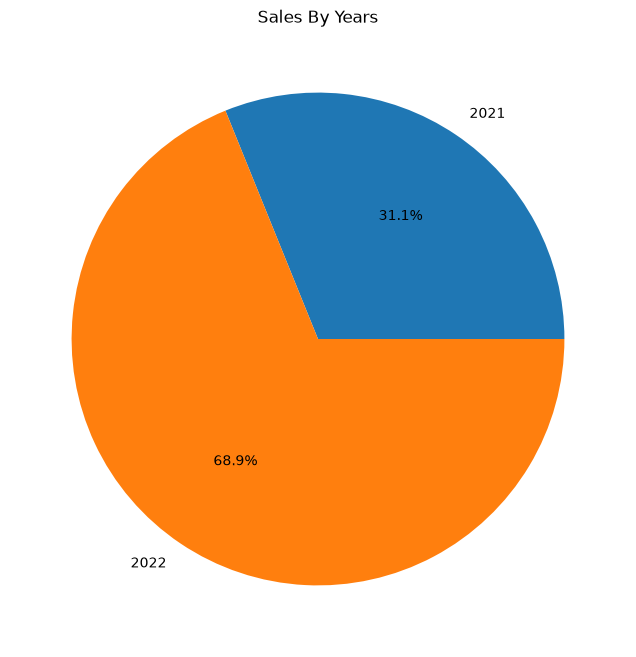

In [6]:
year_sales = df.pivot_table(index='Year', values='Total_sales', aggfunc='sum')

# If you want a normal DataFrame
year_sales = year_sales.reset_index()

print(year_sales)

# Values for pie chart
y = year_sales['Total_sales']

# Labels for pie chart
x = year_sales['Year']

# Create pie chart
plt.figure(figsize=(8, 8))
plt.pie(y, labels=x, autopct='%.1f%%')

plt.title('Sales By Years')
plt.show()

# Monthly sales stats

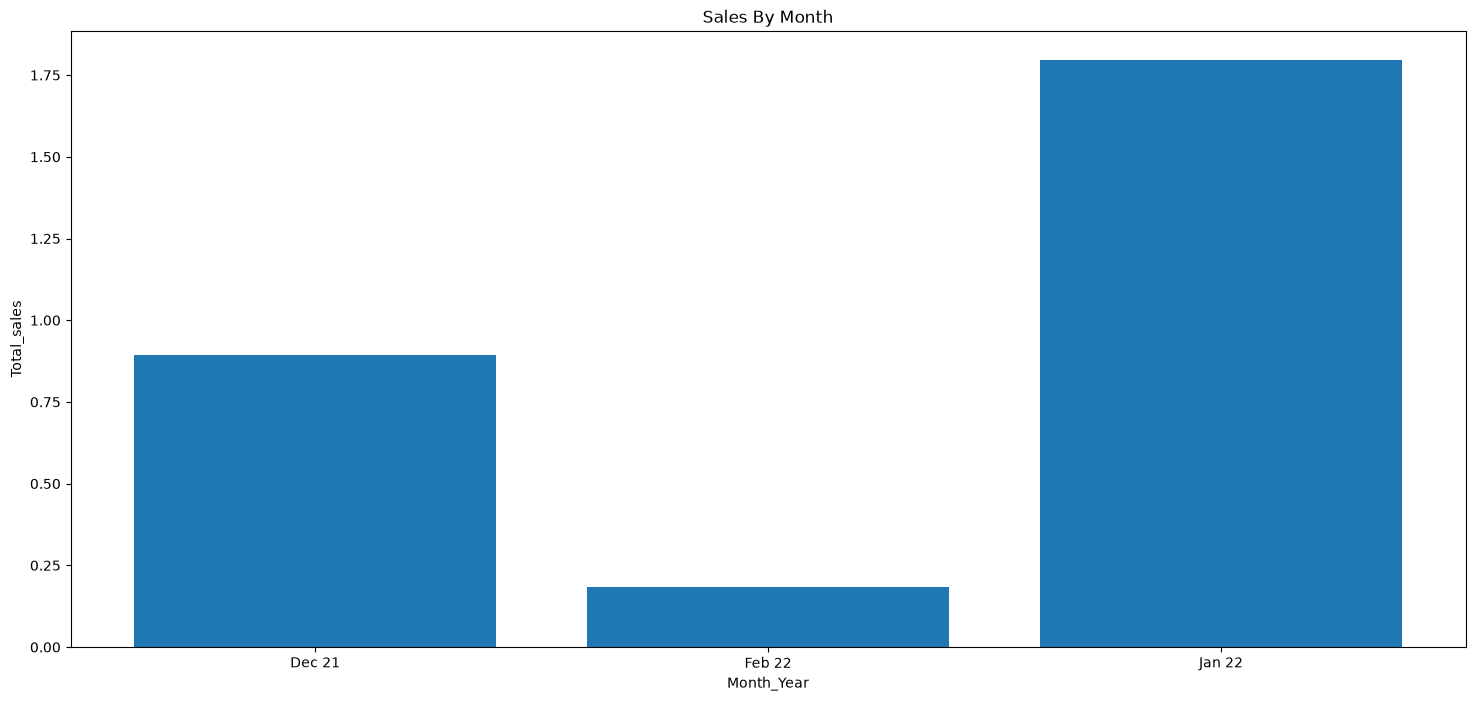

In [7]:
Monthly_sales = df.pivot_table(
    index='Month_Year',
    values='Total_sales',
    aggfunc='sum'
).reset_index()

x = Monthly_sales['Month_Year']
y = Monthly_sales['Total_sales']

plt.figure(figsize=(18, 8))
plt.title('Sales By Month')
plt.xlabel('Month_Year')
plt.ylabel('Total_sales')
plt.bar(x, y)

plt.show()

# Brand Wise Sales

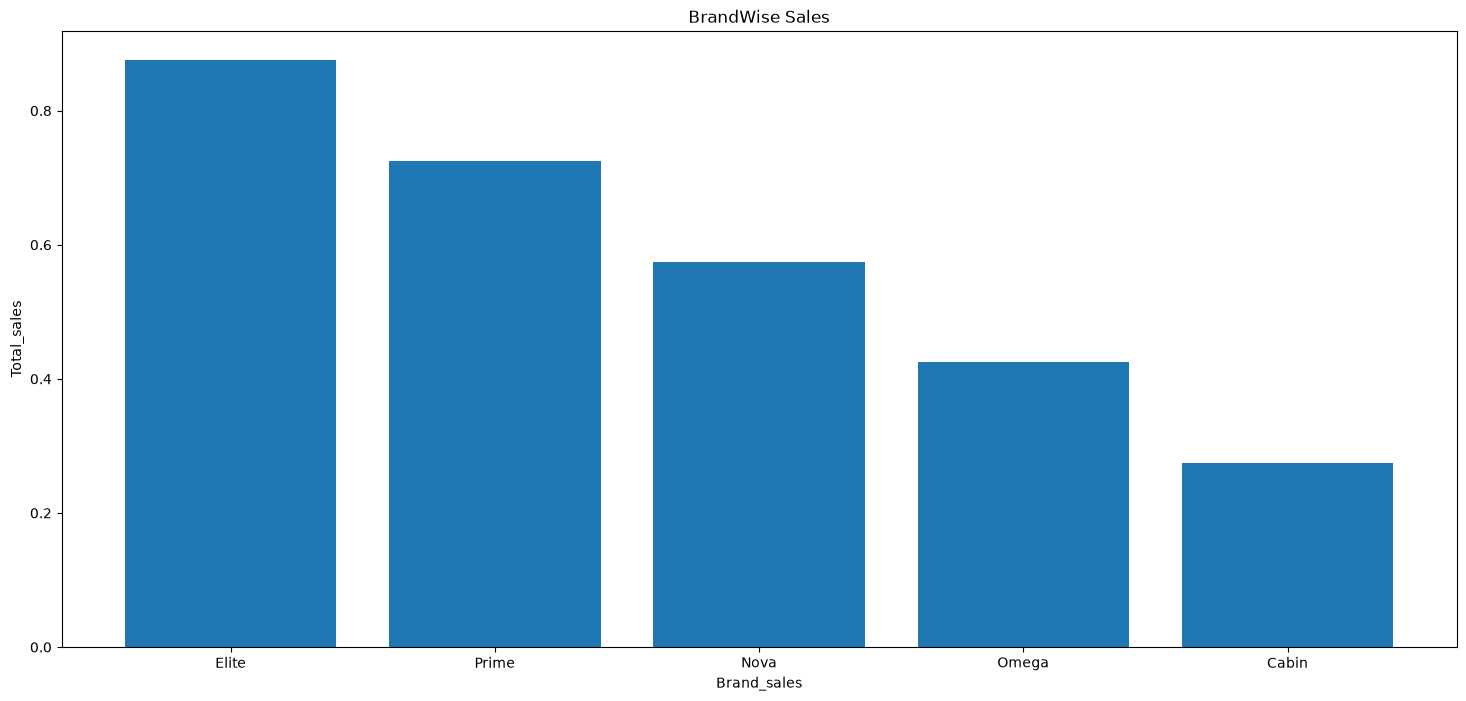

In [8]:
Brand_sales = df.pivot_table(
    index='Brand',
    values='Total_sales',
    aggfunc='sum'
).reset_index()
Brand_sales = Brand_sales.sort_values(by='Total_sales', ascending=False)

x = Brand_sales['Brand']
y = Brand_sales['Total_sales']

plt.figure(figsize=(18, 8))
plt.title('BrandWise Sales')
plt.xlabel('Brand_sales')
plt.ylabel('Total_sales')
plt.bar(x, y)

plt.show()

# Territory Wise Sales

    Territory  Total_sales
0  Faisalabad        0.275
1   Islamabad        0.725
2     Karachi        0.575
3      Lahore        0.425
4      Multan        0.875


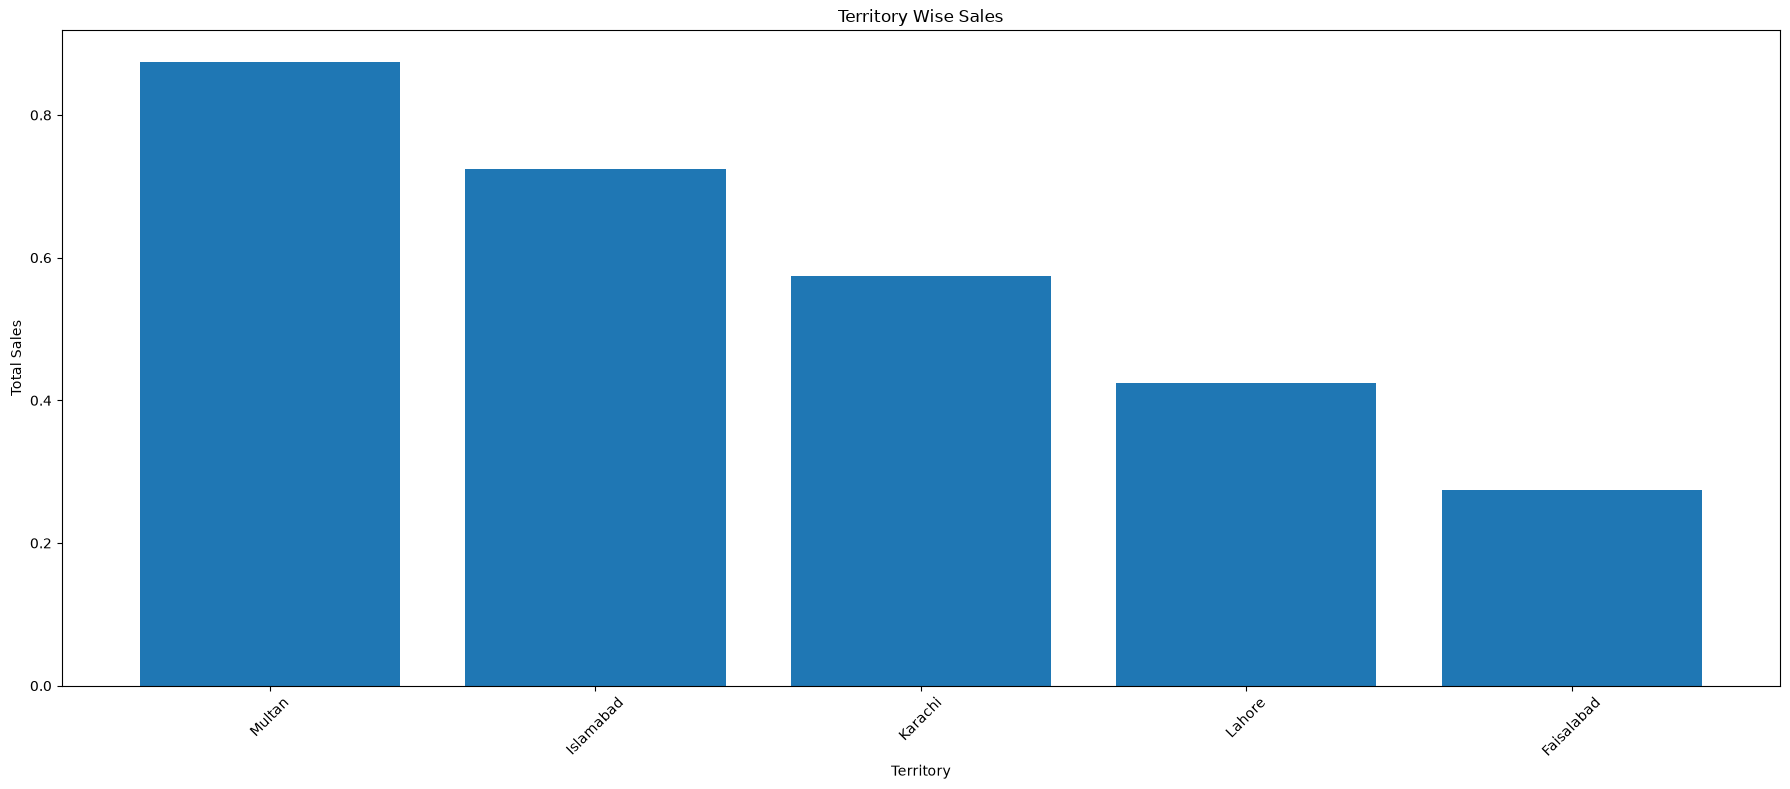

In [9]:
Territory_sales = df.pivot_table(
    index='Territory',
    values='Total_sales',
    aggfunc='sum'
).reset_index()
print(Territory_sales)

# Sort by Total_sales
Territory_sales = Territory_sales.sort_values(
    by='Total_sales',
    ascending=False
)

# X and Y values
x = Territory_sales['Territory']
y = Territory_sales['Total_sales']

# Plot
plt.figure(figsize=(18, 8))
plt.bar(x, y)

plt.title('Territory Wise Sales')
plt.xlabel('Territory')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()